In [27]:
import os
import shutil
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torch.optim import AdamW
from tqdm import tqdm
from torch.cuda import amp
from torch.utils.data import Dataset
import json
from PIL import Image
from torchvision import datasets, transforms
import kagglehub

import matplotlib.pyplot as plt #for section 5
import torchvision.transforms.functional as F # for section #5

# Use current working directory as project root
PROJECT_ROOT = os.getcwd()

# Define the data folder relative to the project root
DATA_DIR = os.path.join(PROJECT_ROOT, "data", "flower_data")
os.makedirs(DATA_DIR, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)

Project root: C:\Projects\DLSem3_Assignment1
Data directory: C:\Projects\DLSem3_Assignment1\data\flower_data


In [4]:
# Download dataset if not already present
if not os.listdir(DATA_DIR):  # folder is empty
    print("Dataset not found. Downloading via KaggleHub...")
    tmp_path = kagglehub.dataset_download("waseemalastal/the-oxford-flowers-102-dataset")
    # Copy everything to our project folder
    shutil.copytree(tmp_path, DATA_DIR, dirs_exist_ok=True)
else:
    print("Dataset already exists in:", DATA_DIR)

Dataset already exists in: C:\Projects\DLSem3_Assignment1\data\flower_data


In [5]:
# Load cat_to_name mapping
with open(os.path.join(DATA_DIR, "cat_to_name.json"), "r") as f:
    cat_to_name = json.load(f)

# Transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])
class TestDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        # List all image files
        self.image_files = sorted([f for f in os.listdir(root_dir)
                                   if f.lower().endswith(('.png', '.jpg', '.jpeg'))])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.image_files[idx])
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        # Return image and filename (no label)
        return image, self.image_files[idx]

# Example usage
# transform = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.ToTensor(),
# ])

# Datasets
train_dataset = datasets.ImageFolder(root=os.path.join(DATA_DIR, "train"), transform=transform)
valid_dataset = datasets.ImageFolder(root=os.path.join(DATA_DIR, "valid"), transform=transform)
test_dataset = TestDataset(root_dir=os.path.join(DATA_DIR, "test"), transform=transform)

# DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=32)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Map numeric labels to class names
def decode_label(label):
    folder_name = train_dataset.classes[label]  # e.g., '1', '2', ...
    return cat_to_name.get(folder_name, folder_name)

# Example
print(f"Number of classes: {len(train_dataset.classes)}")
print(f"First 5 class names: {[decode_label(i) for i in range(5)]}")
print(f"Training samples: {len(train_dataset)}")
print(f"The following is test images")
for images, filenames in test_loader:
    print(filenames)  # shows original file names
    break

Number of classes: 102
First 5 class names: ['pink primrose', 'globe thistle', 'blanket flower', 'trumpet creeper', 'blackberry lily']
Training samples: 6552
The following is test images
('image_00005.jpg', 'image_00006.jpg', 'image_00024.jpg', 'image_00025.jpg', 'image_00029.jpg', 'image_00050.jpg', 'image_00060.jpg', 'image_00065.jpg', 'image_00092.jpg', 'image_00099.jpg', 'image_00114.jpg', 'image_00116.jpg', 'image_00132.jpg', 'image_00176.jpg', 'image_00177.jpg', 'image_00187.jpg', 'image_00191.jpg', 'image_00202.jpg', 'image_00203.jpg', 'image_00204.jpg', 'image_00212.jpg', 'image_00222.jpg', 'image_00239.jpg', 'image_00248.jpg', 'image_00251.jpg', 'image_00258.jpg', 'image_00260.jpg', 'image_00277.jpg', 'image_00282.jpg', 'image_00284.jpg', 'image_00288.jpg', 'image_00291.jpg')


In [15]:
DATA_ROOT = train_dataset
TARGET_SIZE = (34,34)
TARGET_CHANNELS = 3

SAMPLE_IMAGE_PATH = train_dataset[0][0]

SAMPLE_IMAGE_PATH

tensor([[[0.0039, 0.0275, 0.1725,  ..., 0.2118, 0.2353, 0.2314],
         [0.0039, 0.0314, 0.1490,  ..., 0.2392, 0.2392, 0.2353],
         [0.0039, 0.0353, 0.0863,  ..., 0.2431, 0.2392, 0.2392],
         ...,
         [0.0039, 0.0000, 0.0000,  ..., 0.0392, 0.0353, 0.0314],
         [0.0078, 0.0039, 0.0078,  ..., 0.0471, 0.0353, 0.0314],
         [0.0078, 0.0039, 0.0078,  ..., 0.0471, 0.0353, 0.0314]],

        [[0.2039, 0.1725, 0.2431,  ..., 0.2392, 0.2627, 0.2588],
         [0.1961, 0.1765, 0.2275,  ..., 0.2627, 0.2588, 0.2588],
         [0.1843, 0.1765, 0.1725,  ..., 0.2627, 0.2627, 0.2627],
         ...,
         [0.0706, 0.0667, 0.0627,  ..., 0.1451, 0.1412, 0.1373],
         [0.0706, 0.0667, 0.0588,  ..., 0.1451, 0.1333, 0.1255],
         [0.0706, 0.0667, 0.0588,  ..., 0.1451, 0.1333, 0.1255]],

        [[0.0902, 0.1020, 0.2275,  ..., 0.2078, 0.2314, 0.2275],
         [0.0941, 0.1137, 0.2118,  ..., 0.2353, 0.2314, 0.2275],
         [0.0902, 0.1216, 0.1608,  ..., 0.2275, 0.2275, 0.

In [16]:
SAMPLE_IMAGE_PATH.shape

torch.Size([3, 224, 224])

In [ ]:
# Display Original Image
# def display_original_image(sample_path):
#     """Loads and displays the starting image for reference."""
#     print("\n0. Original Image for Reference...")
#     try:
#         # Check if the file exists before attempting to open
#         if not os.path.exists(sample_path):
#             print(f"   -> WARNING: File not found at {sample_path}. Skipping display.")
#             return

#         img = Image.open(sample_path)

#         plt.figure(figsize=(4, 4))
#         plt.imshow(img)
#         plt.title(f"Original Image ({img.size[0]}x{img.size[1]})")
#         plt.axis('off')
#         print(f"   -> Image loaded successfully. Size: {img.size[0]}x{img.size[1]}, Mode: {img.mode}")
#         plt.show() # Display the image

#     except Exception as e:
#         print(f"   -> ERROR loading original image: {e}")

# display_original_image(SAMPLE_IMAGE_PATH)

In [28]:
#section 5
def display_original_image(sample_path):
    print("\n0. Original Image for Reference")
    try:
        if isinstance(sample_path, str):
            if not os.path.exists(sample_path):
                print(f"   -> WARNING, FILE NOT FOUND AT {sample_path}. Skipping Display")
                return
            img = Image.open(sample_path).convert("RGB")
            title = (f" Image size from {sample_path}= (height - {img.size[0]})x (width - {img.size[1]})")
        elif isinstance(sample_path, torch.Tensor):
            img = F.to_pil_image(sample_path)
            img_channel, img_height, img_width = sample_path.shape
            title = (f" Img is tensor img, (-channel = {img_channel}, -height = {img_height}, -width = {img_width}")
        else:
            print(f" the image path must be a file path or a tensor, lol noob try again")
            return
        plt.figure(figsize = (4,4))
        plt.imshow(img)
        plt.title(title)
        plt.axis("off")
        print(f"image loaded and displayed sucessfully")
        plt.show()
                 
    except Exception as e:
        print(f"sunimasei, error loading original image : {e}")
         


0. Original Image for Reference
image loaded and displayed sucessfully


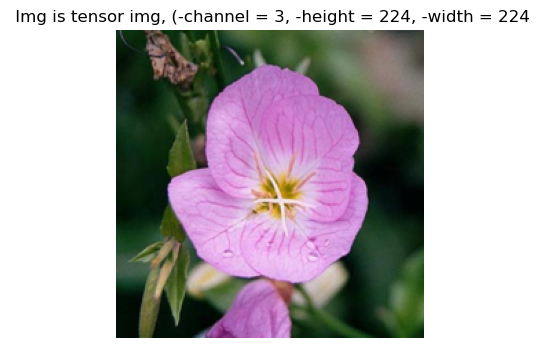

In [29]:
display_original_image(SAMPLE_IMAGE_PATH)